<div dir="rtl" lang="he" xml:lang="he">
<font size=6>עיבוד נתונים - מעבדה ג'</font>

<font size=5> מחברת colab </font>


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.odr import Model, ODR, RealData

In [12]:
file_path = r"/content/לייזרים -מדידות 3, זרם קבוע טמפ לא.xlsx" # Replace with your file path: r"/content/<your file name>.xlsx"
sheet_name = 0 # Replace with your sheet number
data = pd.read_excel(file_path, sheet_name=sheet_name)
data[:5]

,d(cm),I(A),T©,P(mw),I(A).1,T©.1,P(mw).1,dT,dPout,P(mW)
0,32,1.75,20,21.5,1.5,20,10.40,0.028868,0.30960,0.3536
1,32,1.75,21,23.8,1.5,21,11.00,0.028868,0.34272,0.3740
2,32,1.75,22,26.5,1.5,22,12.75,0.028868,0.38160,0.4335
3,32,1.75,23,29.6,1.5,23,15.50,0.028868,0.42624,0.5270
4,32,1.75,24,32.5,1.5,24,17.50,0.028868,0.46800,0.5950


In [13]:
def choose_columns(columns):
    x = data.iloc[:,columns[0]]
    delta_x = data.iloc[:,columns[1]]
    y = data.iloc[:,columns[2]]
    delta_y = data.iloc[:,columns[3]]
    return x, delta_x, y, delta_y

In [14]:
def function(A, x):
    pass # Define your function. See some examples below.

def linear(A, x):
    return A[1] * x + A[0]

def polynomial(A, x):
    return A[2] * x**2 + A[1] * x + A[0]

def optics(A, x):
    return A[1] * x / (x - A[1]) + A[0]

def exponential(A, x):
    return A[2] * np.exp(A[1] * x) + A[0]

def sinusoidal(A, x):
    return A[3] * np.sin(A[1] * x + A[2]) + A[0]
def ours(A,x):
  return A[1]/x+A[0]

In [15]:
def odr_fit(fit_func, initial_guesses, x, delta_x, y, delta_y):
    model = Model(fit_func)
    odr_data = RealData(x, y, sx=delta_x, sy=delta_y)
    odr = ODR(data=odr_data, model=model, beta0=initial_guesses)
    output = odr.run()

    fit_params = output.beta
    fit_params_error = output.sd_beta
    fit_cov = output.cov_beta
    return fit_params, fit_params_error, fit_cov, output

In [16]:
def calc_stats(x, y, fit_params, output):
    residuals = y - fit_func(fit_params, x)
    degrees_of_freedom = len(x) - len(fit_params)
    chi2 = output.sum_square
    chi2_red = chi2/degrees_of_freedom
    p_val = stats.chi2.sf(chi2, degrees_of_freedom)
    return residuals, degrees_of_freedom, chi2_red, p_val

In [17]:
def print_output(fit_params, fit_params_error, chi2_red, p_val, degrees_of_freedom):
    for i in range(len(fit_params)):
        print(f"a[{i}]: {fit_params[i]} \u00B1 {fit_params_error[i]} ({(abs(fit_params_error[i]/fit_params[i]))*100}% error)")
    print(f"chi squared reduced = {chi2_red:.5f} \u00B1 {np.sqrt(2/degrees_of_freedom)}")
    print(f"p-probability = {p_val:.5e}")
    print(f"DOF = {degrees_of_freedom}")

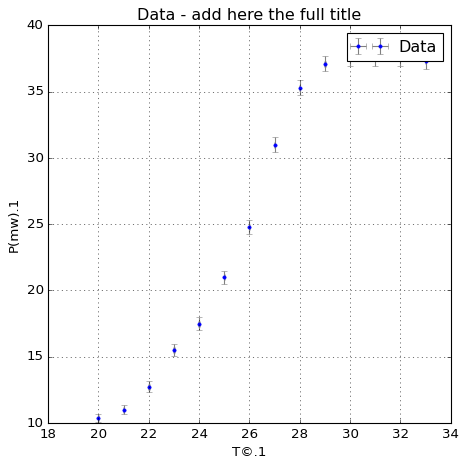

In [18]:
columns = [5,7, 6,8] # Define the columns indices to represent x, delta x, y, delta y.
x, delta_x, y, delta_y = choose_columns(columns)

plt.close('all')
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
plt.style.use('classic')

fig.patch.set_facecolor('white')
ax.set_facecolor('white')

ax.errorbar(x, y, xerr=delta_x, yerr=delta_y, fmt='.b', label='Data', ecolor='gray') # Change the label if needed


ax.set_title('Data - add here the full title')  # Add here the full title for the fit
ax.set_xlabel(f'{data.columns[columns[0]]}') # Change x-axis label if needed
ax.set_ylabel(f'{data.columns[columns[2]]}') # Change y-axis label if needed

ax.grid(True)
ax.legend()

plt.tight_layout()
plt.show()